In [1]:
import sys
sys.path.append("../src")

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import statsmodels.formula.api as smf
from modelado import asignar_estaciones, calcular_grados, filtrar_entrenamiento, calcular_temperatura_media, armar_futuro, pronosticar_cuantiles, maximo_estacional, registrar_ejecucion

In [3]:
ruta_serie = Path("../data/processed/SERIE_TRABAJO_CTRELEUW.csv")
serie = pd.read_csv(ruta_serie, parse_dates=["MES"])
serie.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   MES                        93 non-null     datetime64[us]
 1   MAX_REAL_MW                93 non-null     float64       
 2   POTENCIA_DECLARADA_MW      93 non-null     float64       
 3   EDICION                    93 non-null     str           
 4   DESCARGA                   93 non-null     str           
 5   REVISADO                   93 non-null     bool          
 6   POSIBLE_COPIA_DECLARACION  93 non-null     bool          
 7   TEMPERATURA_MEDIA_C        93 non-null     float64       
 8   TEMPERATURA_MAX_C          93 non-null     float64       
 9   TEMPERATURA_MIN_C          93 non-null     float64       
dtypes: bool(2), datetime64[us](1), float64(5), str(2)
memory usage: 7.7 KB


In [4]:
serie = asignar_estaciones(serie)

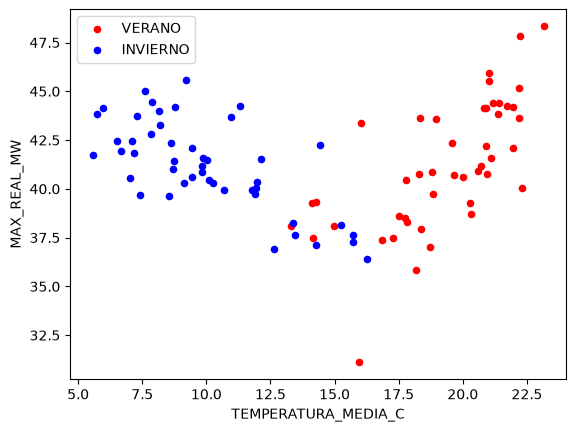

In [5]:
eje_verano = serie[serie["ESTACION"] == "VERANO"].plot.scatter(x="TEMPERATURA_MEDIA_C", y="MAX_REAL_MW",color="red",label="VERANO")
eje_invierno = serie[serie["ESTACION"] == "INVIERNO"].plot.scatter(x="TEMPERATURA_MEDIA_C", y="MAX_REAL_MW",color="blue",label="INVIERNO", ax=eje_verano)


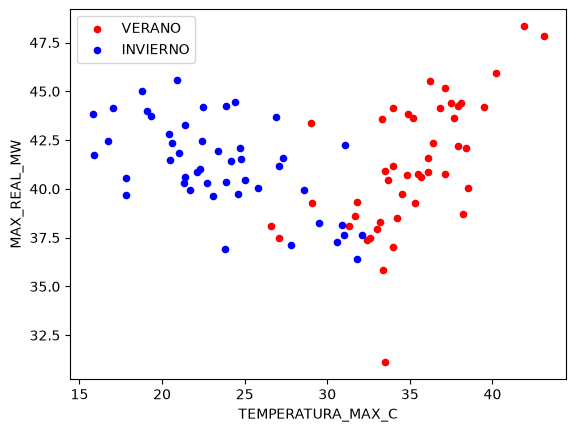

In [6]:
eje_verano = serie[serie["ESTACION"] == "VERANO"].plot.scatter(x="TEMPERATURA_MAX_C", y="MAX_REAL_MW",color="red",label="VERANO")
eje_invierno = serie[serie["ESTACION"] == "INVIERNO"].plot.scatter(x="TEMPERATURA_MAX_C", y="MAX_REAL_MW",color="blue",label="INVIERNO", ax=eje_verano)


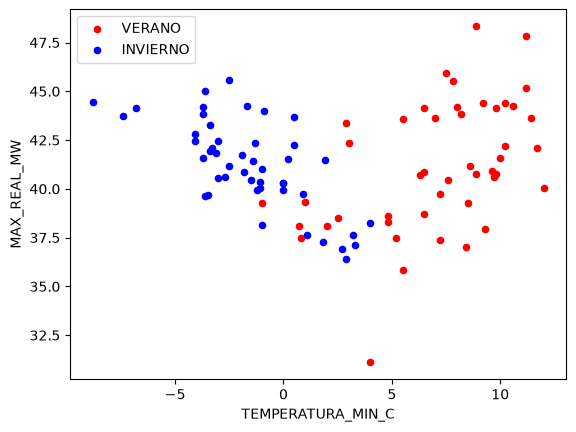

In [7]:
eje_verano = serie[serie["ESTACION"] == "VERANO"].plot.scatter(x="TEMPERATURA_MIN_C", y="MAX_REAL_MW",color="red",label="VERANO")
eje_invierno = serie[serie["ESTACION"] == "INVIERNO"].plot.scatter(x="TEMPERATURA_MIN_C", y="MAX_REAL_MW",color="blue",label="INVIERNO", ax=eje_verano)


In [8]:
serie[serie["ESTACION"] == "VERANO"][["MAX_REAL_MW", "TEMPERATURA_MEDIA_C", "TEMPERATURA_MAX_C", "TEMPERATURA_MIN_C"]].corr()

,MAX_REAL_MW,TEMPERATURA_MEDIA_C,TEMPERATURA_MAX_C,TEMPERATURA_MIN_C
MAX_REAL_MW,1.000000,0.674513,0.626017,0.474927
TEMPERATURA_MEDIA_C,0.674513,1.000000,0.868681,0.865545
TEMPERATURA_MAX_C,0.626017,0.868681,1.000000,0.721567
TEMPERATURA_MIN_C,0.474927,0.865545,0.721567,1.000000


In [9]:
serie[serie["ESTACION"] == "INVIERNO"][["MAX_REAL_MW", "TEMPERATURA_MEDIA_C", "TEMPERATURA_MAX_C", "TEMPERATURA_MIN_C"]].corr()

,MAX_REAL_MW,TEMPERATURA_MEDIA_C,TEMPERATURA_MAX_C,TEMPERATURA_MIN_C
MAX_REAL_MW,1.000000,-0.699452,-0.591989,-0.701277
TEMPERATURA_MEDIA_C,-0.699452,1.000000,0.883706,0.769972
TEMPERATURA_MAX_C,-0.591989,0.883706,1.000000,0.580836
TEMPERATURA_MIN_C,-0.701277,0.769972,0.580836,1.000000


In [10]:
serie = calcular_grados(serie)

In [11]:
serie[["MES","TEMPERATURA_MEDIA_C", "GRADOS_FRIO", "GRADOS_CALOR"]].head()

,MES,TEMPERATURA_MEDIA_C,GRADOS_FRIO,GRADOS_CALOR
0,2019-01-01,21.974194,0.000000,7.974194
1,2019-02-01,21.007143,0.000000,7.007143
2,2019-03-01,18.341935,0.000000,4.341935
3,2019-04-01,16.016667,0.000000,2.016667
4,2019-05-01,11.293548,2.706452,0.000000


In [12]:
entrenamiento = filtrar_entrenamiento(serie)

In [13]:
modelo_cuantil_50 = smf.quantreg("MAX_REAL_MW ~ GRADOS_FRIO + GRADOS_CALOR", entrenamiento)
mediana_ajustada_50 = modelo_cuantil_50.fit(q=0.5)
pred_50 = mediana_ajustada_50.predict(serie)

In [14]:
modelo_cuantil_10 = smf.quantreg("MAX_REAL_MW ~ GRADOS_FRIO + GRADOS_CALOR", entrenamiento)
mediana_ajustada_10 = modelo_cuantil_10.fit(q=0.1)
pred_10 = mediana_ajustada_10.predict(serie)

In [15]:
modelo_cuantil_90 = smf.quantreg("MAX_REAL_MW ~ GRADOS_FRIO + GRADOS_CALOR", entrenamiento)
mediana_ajustada_90 = modelo_cuantil_90.fit(q=0.9)
pred_90 = mediana_ajustada_90.predict(serie)

In [16]:
((pred_10 <= pred_50) & (pred_50 <= pred_90)).all()

np.True_

In [17]:
temp_media = calcular_temperatura_media(serie)
temp_media

MES
1     22.050000
2     21.001801
3     18.859274
4     14.960833
5     10.450403
6      7.671250
7      6.964919
8      9.087500
9     11.487917
10    15.016590
11    18.525714
12    20.173733
Name: TEMPERATURA_MEDIA_C, dtype: float64

In [18]:
futuro = armar_futuro("2026-11-01","2027-04-01",temp_media)

In [19]:
futuro["PRED_10"] = mediana_ajustada_10.predict(futuro)
futuro["PRED_50"] = mediana_ajustada_50.predict(futuro)
futuro["PRED_90"] = mediana_ajustada_90.predict(futuro)


In [20]:
futuro

,MES,TEMPERATURA_MEDIA_C,GRADOS_FRIO,GRADOS_CALOR,PRED_10,PRED_50,PRED_90
0,2026-11-01,18.525714,0.0,4.525714,38.038141,40.831556,44.566223
1,2026-12-01,20.173733,0.0,6.173733,38.764093,42.091490,45.491887
2,2027-01-01,22.050000,0.0,8.050000,39.590589,43.525924,46.545755
3,2027-02-01,21.001801,0.0,7.001801,39.128857,42.724561,45.956999
4,2027-03-01,18.859274,0.0,4.859274,38.185075,41.086567,44.753578
5,2027-04-01,14.960833,0.0,0.960833,36.467812,38.106152,42.563889


In [21]:
tabla_ordenada = pronosticar_cuantiles(entrenamiento, futuro)

In [22]:
tabla_ordenada

,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,0.10,...,0.90,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99
0,35.793712,36.952912,36.952912,36.952942,37.697171,37.975600,37.975631,37.998203,37.999101,38.038141,...,44.566223,44.566224,45.098595,45.118042,45.118077,45.118077,45.118078,45.202523,45.446209,45.446212
1,35.638630,37.360548,37.360548,37.360601,38.649573,38.671257,38.671300,38.702096,38.710837,38.764093,...,45.491887,45.491888,46.238590,46.265867,46.265916,46.265917,46.265917,46.384360,46.519528,46.519530
2,35.462070,37.824641,37.824641,37.824719,39.463262,39.463318,39.503478,39.521147,39.590589,39.733881,...,46.545755,46.759237,47.536474,47.572664,47.572730,47.572730,47.572730,47.729880,47.741500,47.741501
3,35.560708,37.565369,37.565370,37.565434,39.020799,39.020848,39.055777,39.068458,39.128119,39.128857,...,45.956999,45.956999,46.811396,46.842606,46.842663,46.842663,46.842663,46.978189,47.058831,47.058832
4,35.762324,37.035417,37.035418,37.035453,37.889938,38.116401,38.116435,38.140672,38.143157,38.185075,...,44.753578,44.753579,45.329331,45.350362,45.350401,45.350401,45.350401,45.441728,45.663449,45.663452
5,35.637001,36.071124,36.071142,36.071142,36.129175,36.313602,36.459524,36.467812,36.470801,36.470809,...,42.563889,42.563891,42.632635,42.635145,42.635150,42.635150,42.635150,42.646055,43.124478,43.124485


In [23]:
cuantiles_maximo = maximo_estacional(tabla_ordenada)
cuantiles_maximo

array([42.96538548, 45.06035056, 47.05482093])

In [24]:
ruta_registro = Path("../data/registros/EJECUCIONES_PRONOSTICO.csv")
registro = registrar_ejecucion(serie, entrenamiento, "2026-11-01", "2027-04-01", cuantiles_maximo,ruta_registro)
registro .to_csv(ruta_registro, mode="a", header=not ruta_registro.exists(), index=False)